# Week 4: Predictive Modeling and Optimization in Logistics

**Objective:** Predict delivery time and use the predictions to support logistics optimization.

This notebook follows the Week 4 workflow: data loading → inspection → preprocessing → train/test split → model training → evaluation → cross-validation → hyperparameter tuning → delay-risk prediction → optimization recommendations.


## 1. Import Libraries


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", None)


## 2. Load the Dataset


In [2]:
df = pd.read_csv("data/logistics_week4.csv")
print("Dataset shape:", df.shape)
df.head()


Dataset shape: (1200, 7)


,shipping_distance_km,shipment_volume,scheduled_days,transport_cost,region,shipping_mode,actual_delivery_days
0,684,60.05,6,977.67,North,Standard,7
1,927,79.43,3,1364.08,West,Economy,9
2,258,75.55,3,490.91,East,Economy,6
3,946,89.36,2,1460.96,South,Express,5
4,1389,80.77,2,1840.68,South,Economy,11


## 3. Basic Data Inspection


In [3]:
df.info()

print("\nMissing values:")
display(df.isnull().sum().to_frame("missing_values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSummary statistics:")
display(df.describe().T)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   shipping_distance_km  1200 non-null   int64  
 1   shipment_volume       1200 non-null   float64
 2   scheduled_days        1200 non-null   int64  
 3   transport_cost        1200 non-null   float64
 4   region                1200 non-null   object 
 5   shipping_mode         1200 non-null   object 
 6   actual_delivery_days  1200 non-null   int64  
dtypes: float64(2), int64(3), object(2)
memory usage: 65.8+ KB

Missing values:


,missing_values
shipping_distance_km,0
shipment_volume,0
scheduled_days,0
transport_cost,0
region,0
shipping_mode,0
actual_delivery_days,0



Duplicate rows: 0

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
shipping_distance_km,1200.0,744.750833,426.052588,30.00,392.2500,731.50,1108.2500,1499.00
shipment_volume,1200.0,50.938600,28.674789,1.06,25.7275,52.29,75.6050,99.94
scheduled_days,1200.0,4.435833,1.671290,2.00,3.0000,4.00,6.0000,7.00
transport_cost,1200.0,1022.305892,406.466584,143.87,698.5975,1002.21,1360.4025,1935.16
actual_delivery_days,1200.0,6.080833,2.166767,1.00,5.0000,6.00,8.0000,12.00


## 4. Define Features and Target

The target is `actual_delivery_days`. The model uses distance, shipment volume, scheduled delivery time, transport cost, region, and shipping mode as predictors.


In [4]:
X = df.drop(columns=["actual_delivery_days"])
y = df["actual_delivery_days"]

numeric_features = [
    "shipping_distance_km",
    "shipment_volume",
    "scheduled_days",
    "transport_cost"
]

categorical_features = [
    "region",
    "shipping_mode"
]


## 5. Preprocessing Pipeline


In [5]:
preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])


## 6. Train-Test Split


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 960
Testing rows: 240


## 7. Train Linear Regression Baseline


In [7]:
linear_model = Pipeline([
    ("prep", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)


## 8. Train Random Forest Regression


In [8]:
rf_model = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)


## 9. Evaluate Both Models


In [9]:
def evaluate_model(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)
    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

results = pd.DataFrame([
    evaluate_model("Linear Regression", y_test, linear_pred),
    evaluate_model("Random Forest", y_test, rf_pred)
])

results


,Model,MAE,RMSE,R2
0,Linear Regression,0.722286,0.886593,0.844242
1,Random Forest,0.820598,1.003432,0.800484


### Metric Interpretation

- **MAE:** average prediction error in delivery days.
- **RMSE:** gives extra weight to larger prediction errors.
- **R²:** shows how much variation in delivery time is explained by the model.

For this problem, lower MAE/RMSE and higher R² are preferred.


## 10. Cross-Validation


In [10]:
cv_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

print("5-fold CV MAE scores:", -cv_scores)
print("Average CV MAE:", (-cv_scores).mean())


5-fold CV MAE scores: [0.80634113 0.78617459 0.74571869 0.76791323 0.73343083]
Average CV MAE: 0.7679156913357963


## 11. Hyperparameter Tuning


In [11]:
param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [8, 12, None],
    "model__min_samples_leaf": [1, 2, 4]
}

grid = GridSearchCV(
    rf_model,
    param_grid=param_grid,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV MAE:", -grid.best_score_)


Best parameters: {'model__max_depth': 8, 'model__min_samples_leaf': 4, 'model__n_estimators': 100}
Best CV MAE: 0.7465736681352196


## 12. Evaluate the Tuned Model


In [12]:
best_model = grid.best_estimator_
tuned_pred = best_model.predict(X_test)

tuned_results = evaluate_model(
    "Tuned Random Forest",
    y_test,
    tuned_pred
)

pd.DataFrame([tuned_results])


,Model,MAE,RMSE,R2
0,Tuned Random Forest,0.817418,0.992733,0.804716


## 13. Actual vs Predicted Delivery Time


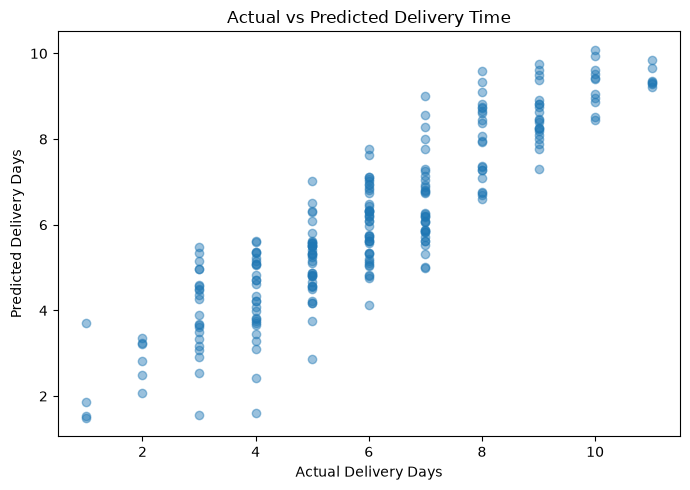

In [13]:
plt.figure(figsize=(7,5))
plt.scatter(y_test, tuned_pred, alpha=0.45)
plt.xlabel("Actual Delivery Days")
plt.ylabel("Predicted Delivery Days")
plt.title("Actual vs Predicted Delivery Time")
plt.tight_layout()
plt.show()


## 14. Predict Delay Risk


In [14]:
prediction_df = X_test.copy()
prediction_df["actual_delivery_days"] = y_test.values
prediction_df["predicted_delivery_days"] = tuned_pred

prediction_df["predicted_delay_days"] = (
    prediction_df["predicted_delivery_days"]
    - prediction_df["scheduled_days"]
)

prediction_df["risk"] = np.where(
    prediction_df["predicted_delay_days"] > 0.5,
    "HIGH",
    "NORMAL"
)

prediction_df.head(10)


,shipping_distance_km,shipment_volume,scheduled_days,transport_cost,region,shipping_mode,actual_delivery_days,predicted_delivery_days,predicted_delay_days,risk
1178,186,74.78,7,536.94,South,Standard,4,4.070440,-2.929560,NORMAL
865,168,23.58,5,422.69,East,Express,4,1.606167,-3.393833,NORMAL
101,369,68.62,3,735.99,North,Standard,6,4.811207,1.811207,HIGH
439,579,5.52,7,615.84,South,Standard,6,5.343493,-1.656507,NORMAL
58,522,28.04,2,774.62,East,Express,5,2.875813,0.875813,HIGH
1120,871,52.56,5,1225.00,North,Standard,6,6.314149,1.314149,HIGH
323,643,41.62,3,783.94,West,Express,1,3.700505,0.700505,HIGH
974,1075,51.22,2,1390.21,North,Standard,8,7.343182,5.343182,HIGH
411,1331,87.45,2,1774.07,North,Express,6,6.953772,4.953772,HIGH
855,128,80.60,5,515.27,West,Standard,5,4.168835,-0.831165,NORMAL


## 15. High-Risk Shipment Summary


In [15]:
risk_summary = (
    prediction_df["risk"]
    .value_counts()
    .rename_axis("risk_level")
    .reset_index(name="shipments")
)

risk_summary


,risk_level,shipments
0,HIGH,170
1,NORMAL,70


## 16. Simple Optimization Strategy


In [16]:
def recommended_action(row):
    if row["risk"] == "HIGH":
        if row["shipping_mode"] != "Express":
            return "Review route / consider premium service"
        return "Prioritize dispatch and review route"
    return "Proceed with standard plan"

prediction_df["recommended_action"] = prediction_df.apply(
    recommended_action, axis=1
)

prediction_df[[
    "shipping_distance_km",
    "shipping_mode",
    "scheduled_days",
    "predicted_delivery_days",
    "risk",
    "recommended_action"
]].head(10)


,shipping_distance_km,shipping_mode,scheduled_days,predicted_delivery_days,risk,recommended_action
1178,186,Standard,7,4.070440,NORMAL,Proceed with standard plan
865,168,Express,5,1.606167,NORMAL,Proceed with standard plan
101,369,Standard,3,4.811207,HIGH,Review route / consider premium service
439,579,Standard,7,5.343493,NORMAL,Proceed with standard plan
58,522,Express,2,2.875813,HIGH,Prioritize dispatch and review route
1120,871,Standard,5,6.314149,HIGH,Review route / consider premium service
323,643,Express,3,3.700505,HIGH,Prioritize dispatch and review route
974,1075,Standard,2,7.343182,HIGH,Review route / consider premium service
411,1331,Express,2,6.953772,HIGH,Prioritize dispatch and review route
855,128,Standard,5,4.168835,NORMAL,Proceed with standard plan


## 17. Optimization Recommendations

The model can support operational decisions in several ways:

1. **Prioritize high-risk shipments** before they become late.
2. **Allocate extra vehicle or warehouse capacity** to periods with higher predicted delay risk.
3. **Review long-distance routes** where predicted delivery time is high.
4. **Use premium transport selectively** instead of upgrading every shipment.
5. **Track actual versus predicted delivery time** and retrain the model as logistics patterns change.

The goal is not simply to minimize delivery time. A practical logistics strategy should balance reliability, capacity, and transportation cost.


## 18. Week 4 Outcome

The notebook converts logistics data into a predictive workflow that estimates delivery time and identifies shipments that may need attention. The model results can then be connected to practical actions such as route review, resource allocation, and service-level decisions.

This creates the foundation for more advanced work such as real-time delay prediction, vehicle-routing optimization, and automated logistics decision support.
